# Diabetes 130-Hospitals: EDA

10 years of inpatient records (1999-2008) from 130 US hospitals, all diabetic patients. One
row is one hospital stay.

Which discharged patients come back within 30 days. Each chart is followed by a finding.
These are associations, not proof.

## 1. Setup and overview

Load the file and convert `?` to NaN. Without that, pandas treats `?` as a normal string and
`.isna()` returns zero.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
sns.set_style("whitegrid")

df = pd.read_csv("../data/diabetic_data.csv", low_memory=False)
df = df.replace("?", np.nan)

df.shape

(101766, 50)

In [2]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
df.dtypes.value_counts()

object    37
int64     13
Name: count, dtype: int64

Three values collapse to a binary flag for the 30-day window, since that is what hospitals
are measured on. Grouping `>30` with `NO` loses information but matches the question.

In [4]:
df["readmitted_30d"] = (df["readmitted"] == "<30").astype(int)

df["readmitted"].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

### Missing values

In [5]:
missing = pd.DataFrame({
    "count": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(2),
})
missing = missing[missing["count"] > 0].sort_values("percent", ascending=False)
missing

,count,percent
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


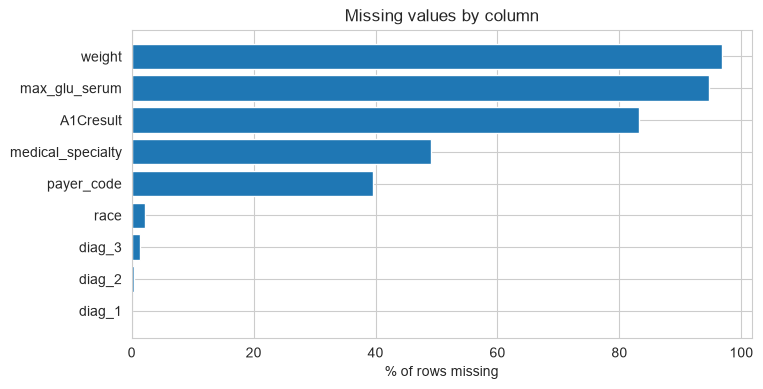

In [6]:
plt.figure(figsize=(8, 4))
plt.barh(missing.index[::-1], missing["percent"][::-1])
plt.xlabel("% of rows missing")
plt.title("Missing values by column")
plt.show()

**Finding:** Five columns are missing heavily: `weight` (96.9%), `max_glu_serum` (94.8%),
`A1Cresult` (83.3%), `medical_specialty` (49.1%), `payer_code` (39.6%).

`weight` is unusable. The two lab columns are different, as section 5 shows.

## 2. Target balance

How many stays actually ended in a readmission within 30 days.

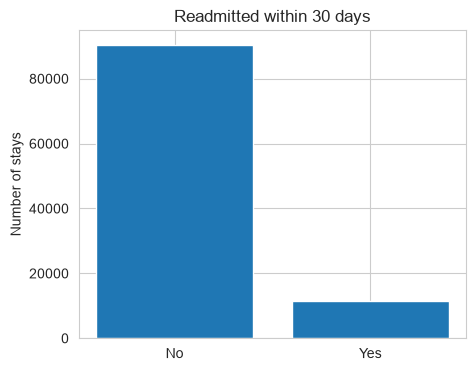

readmitted_30d
0    90409
1    11357
Name: count, dtype: int64
positive rate: 11.16%


In [7]:
counts = df["readmitted_30d"].value_counts().sort_index()

plt.figure(figsize=(5, 4))
plt.bar(["No", "Yes"], counts.values)
plt.ylabel("Number of stays")
plt.title("Readmitted within 30 days")
plt.show()

print(counts)
print("positive rate: %.2f%%" % (df["readmitted_30d"].mean() * 100))

**Finding:** 11.2% of stays end in a readmission, roughly 1 in 9.

Predicting "nobody comes back" would be 88.8% accurate and useless, so modelling uses AUC and
recall. Blanket follow-up would miss eight times out of nine.

## 3. Univariate

### Age

`age` comes bucketed as a string like `[70-80)`, so it gets a bar chart.

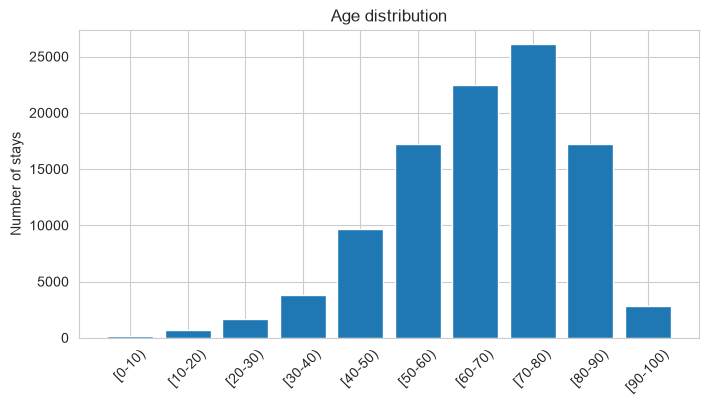

In [8]:
age_counts = df["age"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
plt.bar(age_counts.index, age_counts.values)
plt.xticks(rotation=45)
plt.ylabel("Number of stays")
plt.title("Age distribution")
plt.show()

**Finding:** 67% of stays are patients aged 60 or over, 70-80 the largest band.

A follow-up programme on this data is a programme for older patients.

### Race and gender

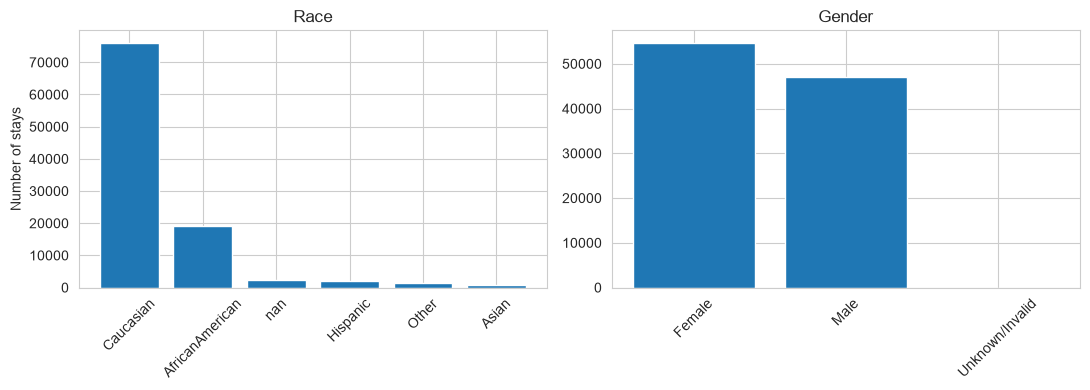

race
Caucasian          76099
AfricanAmerican    19210
NaN                 2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64


In [9]:
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
race_counts = df["race"].value_counts(dropna=False)
plt.bar(race_counts.index.astype(str), race_counts.values)
plt.xticks(rotation=45)
plt.ylabel("Number of stays")
plt.title("Race")

plt.subplot(1, 2, 2)
gender_counts = df["gender"].value_counts()
plt.bar(gender_counts.index, gender_counts.values)
plt.xticks(rotation=45)
plt.title("Gender")

plt.tight_layout()
plt.show()

print(race_counts)

**Finding:** 75% Caucasian, 19% African American. Hispanic, Asian and Other are under 4%
together, with Asian at 641 stays.

Model performance for the small groups will be noisy, so report sample sizes with it.

### Numeric columns

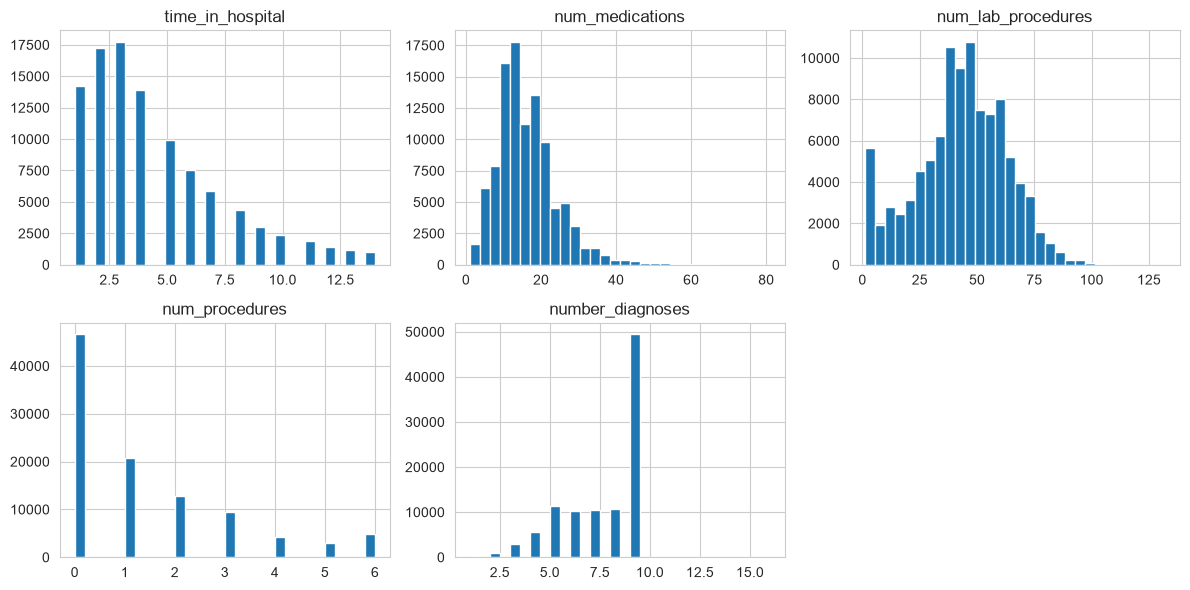

time_in_hospital      1.13
num_medications       1.33
num_lab_procedures   -0.24
num_procedures        1.32
number_diagnoses     -0.88
dtype: float64


In [10]:
numeric_cols = ["time_in_hospital", "num_medications", "num_lab_procedures",
                "num_procedures", "number_diagnoses"]

df[numeric_cols].hist(figsize=(12, 6), bins=30, layout=(2, 3))
plt.tight_layout()
plt.show()

print(df[numeric_cols].skew().round(2))

**Finding:** `time_in_hospital`, `num_medications` and `num_procedures` are right-skewed
(1.1 to 1.3). Median stay 4 days, median medication count 15.

`number_diagnoses` is left-skewed, capped at 16.

## 4. Outliers

Checking whether the long tails are errors or real patients.

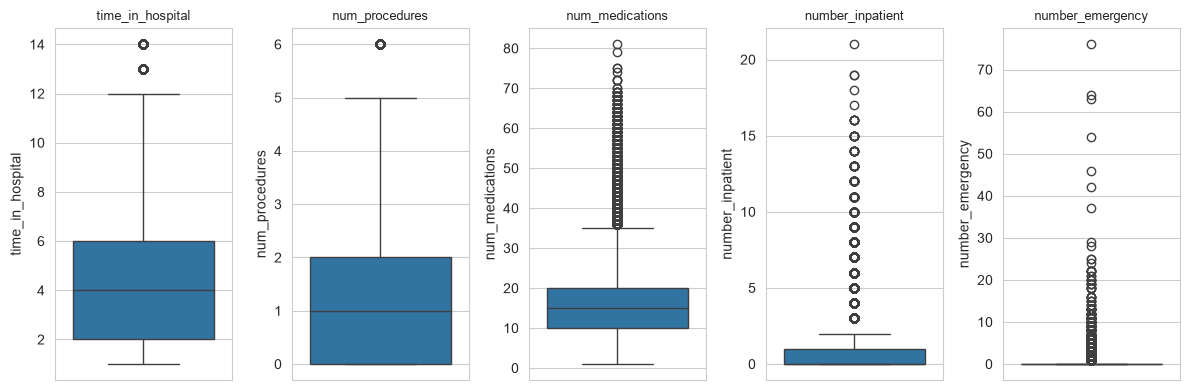

,time_in_hospital,num_procedures,num_medications,number_inpatient,number_emergency
50%,4.0,1.0,15.0,0.0,0.0
75%,6.0,2.0,20.0,1.0,0.0
max,14.0,6.0,81.0,21.0,76.0


In [11]:
outlier_cols = ["time_in_hospital", "num_procedures", "num_medications",
                "number_inpatient", "number_emergency"]

plt.figure(figsize=(12, 4))
for i, col in enumerate(outlier_cols, start=1):
    plt.subplot(1, 5, i)
    sns.boxplot(y=df[col])
    plt.title(col, fontsize=9)
plt.tight_layout()
plt.show()

df[outlier_cols].describe().loc[["50%", "75%", "max"]]

**Finding:** The tails are real. `number_emergency` reaches 76 visits a year and
`number_inpatient` reaches 21, both on a smooth tail.

These are the patients a programme is for, so they are kept rather than clipped.

## 5. Against readmission

Charts now show readmission rate within each group, not counts. The dashed line is the
overall 11.2%.

### Insulin

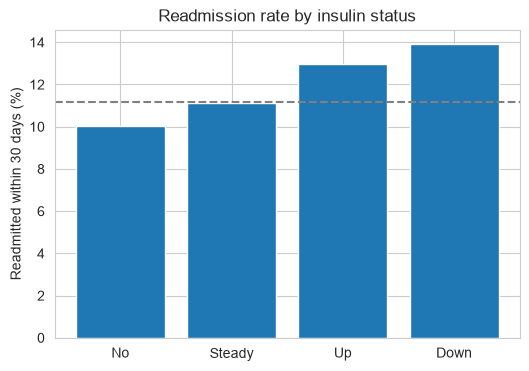

,mean,size
insulin,,
No,0.1004,47383
Steady,0.1113,30849
Up,0.1299,11316
Down,0.1390,12218


In [12]:
overall = df["readmitted_30d"].mean()

insulin = df.groupby("insulin")["readmitted_30d"].agg(["mean", "size"])
insulin = insulin.reindex(["No", "Steady", "Up", "Down"])

plt.figure(figsize=(6, 4))
plt.bar(insulin.index, insulin["mean"] * 100)
plt.axhline(overall * 100, linestyle="--", color="grey")
plt.ylabel("Readmitted within 30 days (%)")
plt.title("Readmission rate by insulin status")
plt.show()

insulin.round(4)

**Finding:** Dose changes return most often: 13.9% decreased, 13.0% increased, against 11.1%
steady and 10.0% on no insulin.

An adjusted dose suggests the patient was not yet stable at discharge. No insulin is the
lowest group.

### Length of stay

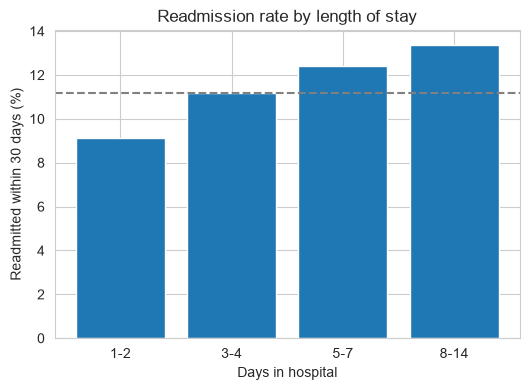

,mean,size
time_in_hospital,,
1-2,0.0914,31432
3-4,0.1117,31680
5-7,0.1241,23364
8-14,0.1337,15290


In [13]:
stay_bins = pd.cut(df["time_in_hospital"], bins=[0, 2, 4, 7, 14],
                   labels=["1-2", "3-4", "5-7", "8-14"])

stay = df.groupby(stay_bins, observed=True)["readmitted_30d"].agg(["mean", "size"])

plt.figure(figsize=(6, 4))
plt.bar(stay.index.astype(str), stay["mean"] * 100)
plt.axhline(overall * 100, linestyle="--", color="grey")
plt.xlabel("Days in hospital")
plt.ylabel("Readmitted within 30 days (%)")
plt.title("Readmission rate by length of stay")
plt.show()

stay.round(4)

**Finding:** Rises with length of stay, but only from 9.1% to 13.4%.

Weak on its own since even the worst group returns under 14% of the time. Useful in a model,
not as a policy.

### Previous inpatient admissions

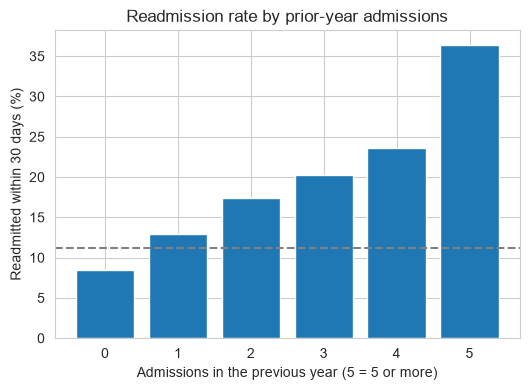

,mean,size
number_inpatient,,
0,0.0844,67630
1,0.1292,19521
2,0.1743,7566
3,0.2029,3411
4,0.2361,1622
5,0.3641,2016


In [14]:
prior = df.groupby(df["number_inpatient"].clip(upper=5))["readmitted_30d"].agg(["mean", "size"])

plt.figure(figsize=(6, 4))
plt.bar(prior.index.astype(str), prior["mean"] * 100)
plt.axhline(overall * 100, linestyle="--", color="grey")
plt.xlabel("Admissions in the previous year (5 = 5 or more)")
plt.ylabel("Readmitted within 30 days (%)")
plt.title("Readmission rate by prior-year admissions")
plt.show()

prior.round(4)

**Finding:** The strongest signal. 8.4% at no prior admissions, 36.4% at five or more,
rising at every step.

Available at admission from existing records. It mostly identifies patients staff already
recognise.

### The two lab tests

83% and 95% missing. A missing value means the test was not ordered, so the result and
whether it happened are worth separating.

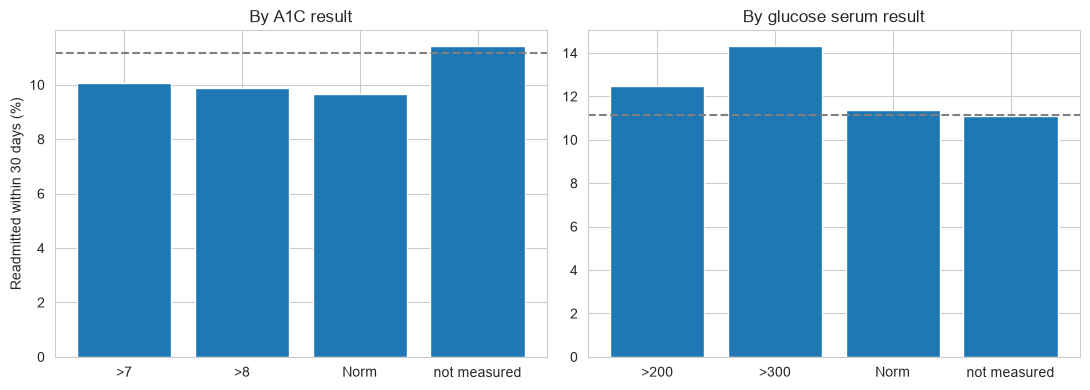

                mean   size
A1Cresult                  
>7            0.1005   3812
>8            0.0987   8216
Norm          0.0966   4990
not measured  0.1142  84748
                 mean   size
max_glu_serum               
>200           0.1246   1485
>300           0.1432   1264
Norm           0.1136   2597
not measured   0.1109  96420


In [15]:
a1c = df.groupby(df["A1Cresult"].fillna("not measured"))["readmitted_30d"].agg(["mean", "size"])
glucose = df.groupby(df["max_glu_serum"].fillna("not measured"))["readmitted_30d"].agg(["mean", "size"])

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.bar(a1c.index.astype(str), a1c["mean"] * 100)
plt.axhline(overall * 100, linestyle="--", color="grey")
plt.ylabel("Readmitted within 30 days (%)")
plt.title("By A1C result")

plt.subplot(1, 2, 2)
plt.bar(glucose.index.astype(str), glucose["mean"] * 100)
plt.axhline(overall * 100, linestyle="--", color="grey")
plt.title("By glucose serum result")

plt.tight_layout()
plt.show()

print(a1c.round(4))
print(glucose.round(4))

**Finding:** Among patients tested, the result barely matters: 9.9% for A1C above 8 against
9.7% for normal.

The variation is in the "not measured" bar, which the next chart isolates.

### Was the test ordered?

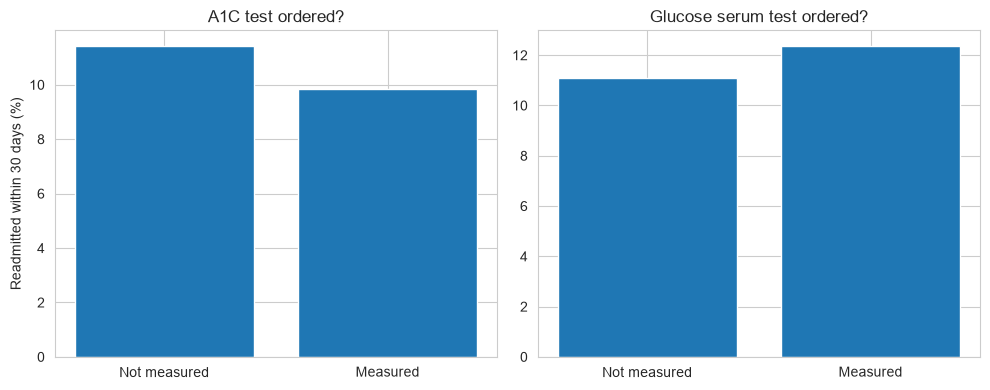

                mean   size
a1c_measured               
False         0.1142  84748
True          0.0985  17018
                    mean   size
glucose_measured               
False             0.1109  96420
True              0.1236   5346


In [16]:
df["a1c_measured"] = df["A1Cresult"].notna()
df["glucose_measured"] = df["max_glu_serum"].notna()

a1c_flag = df.groupby("a1c_measured")["readmitted_30d"].agg(["mean", "size"])
glucose_flag = df.groupby("glucose_measured")["readmitted_30d"].agg(["mean", "size"])

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.bar(["Not measured", "Measured"], a1c_flag["mean"] * 100)
plt.ylabel("Readmitted within 30 days (%)")
plt.title("A1C test ordered?")

plt.subplot(1, 2, 2)
plt.bar(["Not measured", "Measured"], glucose_flag["mean"] * 100)
plt.title("Glucose serum test ordered?")

plt.tight_layout()
plt.show()

print(a1c_flag.round(4))
print(glucose_flag.round(4))

**Finding:** The two point opposite ways. A1C not ordered gives 11.42% against 9.85%; glucose
ordered gives 12.36% against 11.09%.

An A1C is a planned check and 83% never got one. A glucose test is ordered when a patient is
unstable.

## 6. Correlation

Checking whether any of the numeric columns are measuring the same thing.

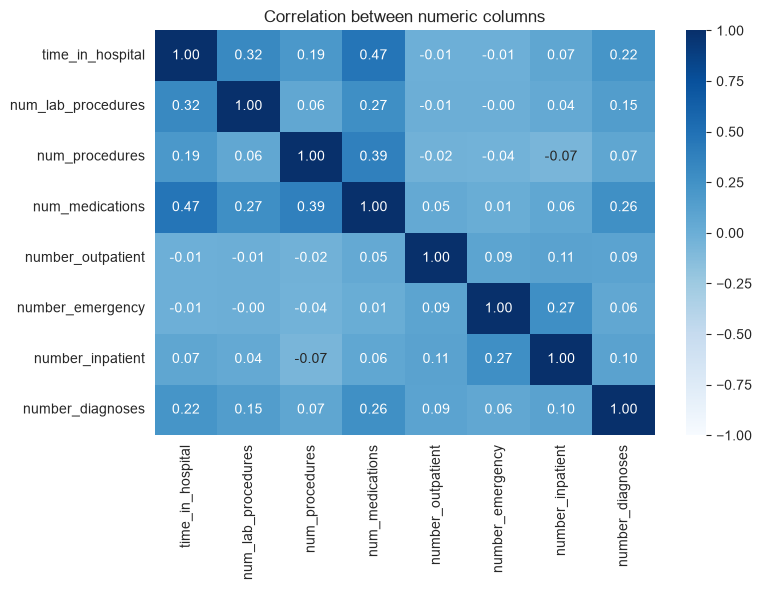

In [17]:
corr_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures",
             "num_medications", "number_outpatient", "number_emergency",
             "number_inpatient", "number_diagnoses"]

corr = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1)
plt.title("Correlation between numeric columns")
plt.tight_layout()
plt.show()

In [18]:
# pairs worth a look
pairs = []
for i in range(len(corr_cols)):
    for j in range(i + 1, len(corr_cols)):
        r = corr.iloc[i, j]
        if abs(r) > 0.2:
            pairs.append((corr_cols[i], corr_cols[j], round(r, 3)))

pd.DataFrame(pairs, columns=["col_1", "col_2", "r"]).sort_values("r", ascending=False)

,col_1,col_2,r
1,time_in_hospital,num_medications,0.466
4,num_procedures,num_medications,0.386
0,time_in_hospital,num_lab_procedures,0.318
3,num_lab_procedures,num_medications,0.268
6,number_emergency,number_inpatient,0.267
5,num_medications,number_diagnoses,0.262
2,time_in_hospital,number_diagnoses,0.220


**Finding:** Nothing is redundant. The strongest pair is `time_in_hospital` and
`num_medications` at r = 0.47.

Nothing reaches 0.7, so all eight columns stay in.

## 7. Summary

- Prior-year admissions is the strongest field: 8.4% readmission at zero, 36.4% at five or more.
- 83% of stays never got an A1C test, and that group returns more often (11.42% vs 9.85%).
- Insulin dose changes mark unstable patients: 13.0-13.9% against 10.0% for patients on none.
- The long tails are real patients, so they are kept rather than clipped.
- 11.2% of stays end in a readmission, so accuracy is not a usable metric.

For modelling: split by patient (71,518 patients across 101,766 stays), and drop the 2,423
stays with an expired or hospice discharge code.